In [1]:
import numpy, scipy, pandas, matplotlib
print("siap")

siap


In [2]:
from scipy.io import wavfile
fs, x = wavfile.read("../data/raw/A5-w40khzrw1.wav")
print(fs, x.shape, x.dtype)

50000 (500000,) int16


In [3]:
from scipy.io import wavfile
import pandas as pd

files = [
    "A3-pvdfrw1.wav",
    "A4-accelrw.wav",
    "A5-w40khzrw1.wav",
    "A6-w30khzrw1.wav",
    "A7-piezorw1.wav",
    "A8-sz-lm3r1_f3-0s.wav",
    "A9-sza-mar1f5-0s.wav",
]

hasil = []
for f in files:
    fs, x = wavfile.read(f"../data/raw/{f}")
    durasi = durasi = len(x) / fs                     # isi: jumlah sampel dibagi fs
    hasil.append({"file": f, "fs_hz": fs, "durasi_s": round(durasi, 1)})

df = pd.DataFrame(hasil)                # isi: list yang berisi dict tadi
df

,file,fs_hz,durasi_s
0,A3-pvdfrw1.wav,25000,10.0
1,A4-accelrw.wav,25000,10.0
2,A5-w40khzrw1.wav,50000,10.0
3,A6-w30khzrw1.wav,50000,10.0
4,A7-piezorw1.wav,25000,10.0
5,A8-sz-lm3r1_f3-0s.wav,20000,20.9
6,A9-sza-mar1f5-0s.wav,20000,18.7


In [4]:
df.to_csv("../results/inventaris.csv", index=False)

In [5]:
import numpy as np
import matplotlib.pyplot as plt

fs, x = wavfile.read("../data/raw/A5-w40khzrw1.wav")
x = x.astype(float)
x = x - x.mean()
t = np.arange(len(x)) / fs

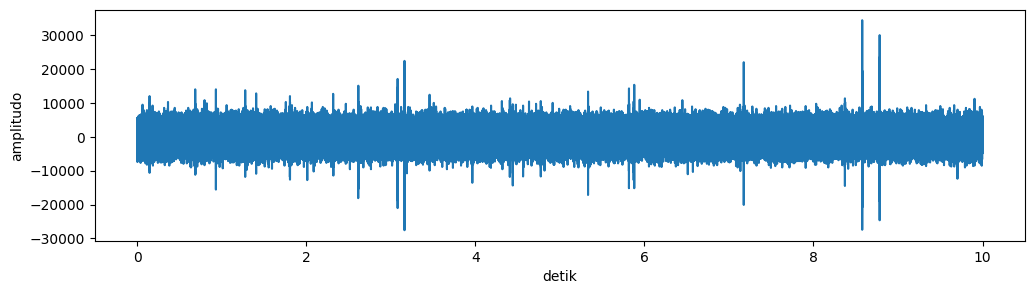

In [6]:
plt.figure(figsize=(12, 3))
plt.plot(t, x)
plt.xlabel("detik")
plt.ylabel("amplitudo")
plt.show()

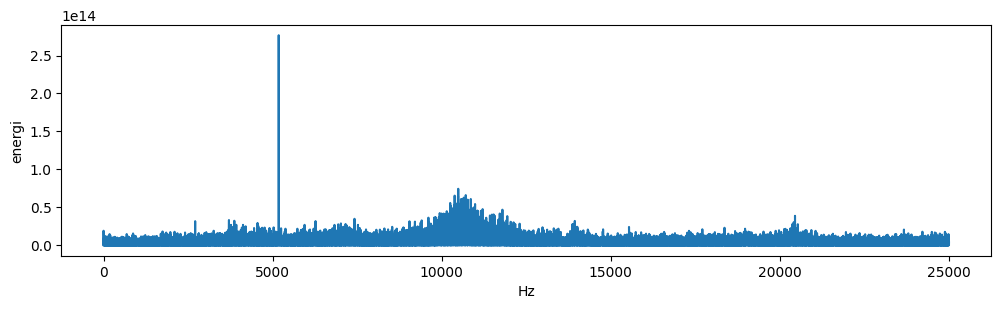

In [7]:
X = np.fft.rfft(x)
f = np.fft.rfftfreq(len(x), 1/fs)
plt.figure(figsize=(12, 3))
plt.plot(f, np.abs(X)**2)
plt.xlabel("Hz")
plt.ylabel("energi")
plt.show()

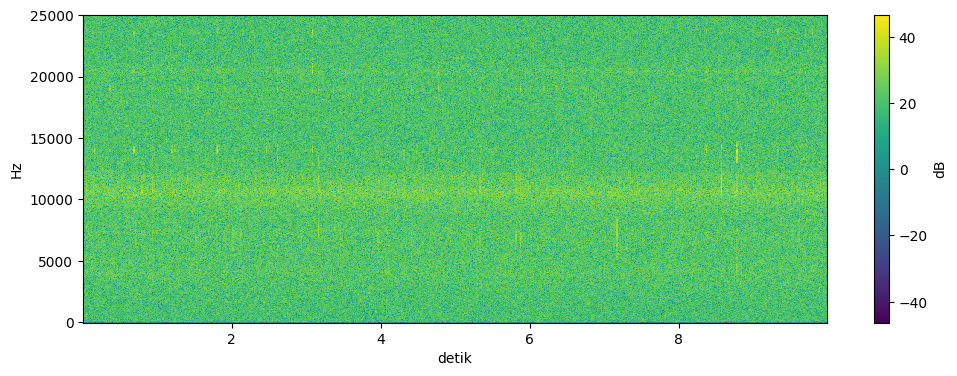

In [8]:
from scipy.signal import spectrogram
ff, tt, S = spectrogram(x, fs, nperseg=int(fs*0.02), noverlap=int(fs*0.01))
plt.figure(figsize=(12, 4))
plt.pcolormesh(tt, ff, 10*np.log10(S + 1e-12), shading="auto")
plt.xlabel("detik")
plt.ylabel("Hz")
plt.colorbar(label="dB")
plt.show()

In [9]:
plt.savefig("../results/spektrum_A5.png", dpi=150)

<Figure size 640x480 with 0 Axes>

In [10]:
n = int(fs * 0.01)
m = len(x) // n
frames = x[:m*n].reshape(m, n)
rms = np.sqrt((frames**2).mean(axis=1))

med = np.median(rms)
mad = np.median(np.abs(rms - med))
ambang = med + 3*mad
aktif = rms > ambang

d = np.diff(np.concatenate([[0], aktif.astype(int), [0]]))
mulai = np.where(d == 1)[0]
akhir = np.where(d == -1)[0]

event = pd.DataFrame({"mulai_s": mulai*0.01, "akhir_s": akhir*0.01})
event["durasi_ms"] = (event.akhir_s - event.mulai_s) * 1000
print(len(event), "event, ambang =", round(ambang, 1))
event.head()

60 event, ambang = 2499.0


,mulai_s,akhir_s,durasi_ms
0,0.14,0.16,20.0
1,0.36,0.37,10.0
2,0.67,0.70,30.0
3,0.71,0.72,10.0
4,0.79,0.80,10.0


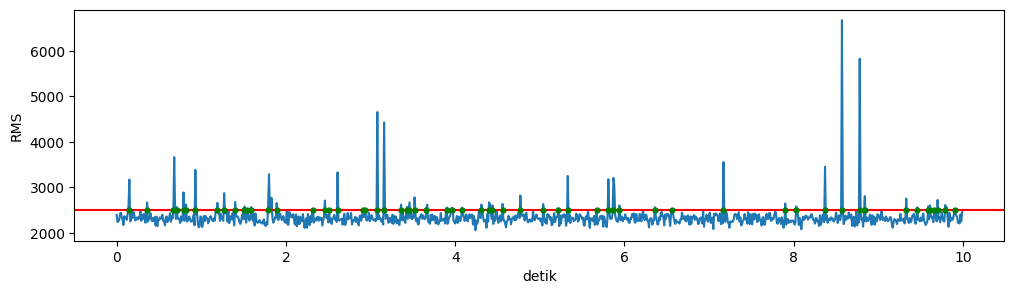

In [11]:
tf = np.arange(m) * 0.01
plt.figure(figsize=(12, 3))
plt.plot(tf, rms)
plt.axhline(ambang, color="r")
plt.scatter(event.mulai_s, [ambang]*len(event), color="g", s=12, zorder=3)
plt.xlabel("detik"); plt.ylabel("RMS")
plt.savefig("../results/rms_event_A5.png", dpi=150)
plt.show()

In [12]:
event.to_csv("../results/event_A5.csv", index=False)

In [13]:
from fractions import Fraction
from scipy.signal import welch, resample_poly, firwin

def dengan_filter(x, fs, fs_baru):
    r = Fraction(fs_baru, fs)
    return resample_poly(x, r.numerator, r.denominator)

def tanpa_filter(x, fs, fs_baru):
    r = Fraction(fs_baru, fs)
    up, down = r.numerator, r.denominator
    h = np.array([1.0]) if up == 1 else firwin(2*10*max(up, down)+1, 1/up)
    return resample_poly(x, up, down, window=h)

def energi_hilang(x, fs, fs_baru):
    P = np.abs(np.fft.rfft(x))**2
    f = np.fft.rfftfreq(len(x), 1/fs)
    return 100 * P[f > fs_baru/2].sum() / P.sum()

def lsd(x, fs, y, fs_baru, nper=4096):
    f0, P0 = welch(x, fs, nperseg=nper)
    f1, P1 = welch(y, fs_baru, nperseg=int(round(nper*fs_baru/fs)))
    mk = f1 <= 0.4*fs_baru
    P0i = np.interp(f1[mk], f0, P0)
    dB = 10*np.log10(P0i + 1e-20) - 10*np.log10(P1[mk] + 1e-20)
    return np.sqrt(np.mean(dB**2))

In [14]:
baris = []
for fs_baru in [25000, 16000, 12500, 8000]:
    y1 = tanpa_filter(x, fs, fs_baru)
    y2 = dengan_filter(x, fs, fs_baru)
    baris.append({
        "fs_baru": fs_baru,
        "energi_hilang_pct": round(energi_hilang(x, fs, fs_baru), 1),
        "lsd_tanpa_filter_dB": round(lsd(x, fs, y1, fs_baru), 2),
        "lsd_dengan_filter_dB": round(lsd(x, fs, y2, fs_baru), 2),
    })
hasil_rs = pd.DataFrame(baris)
hasil_rs.to_csv("../results/resampling_A5.csv", index=False)
hasil_rs

,fs_baru,energi_hilang_pct,lsd_tanpa_filter_dB,lsd_dengan_filter_dB
0,25000,39.4,2.63,0.01
1,16000,71.1,5.56,0.07
2,12500,79.0,7.21,0.01
3,8000,88.1,9.58,0.07


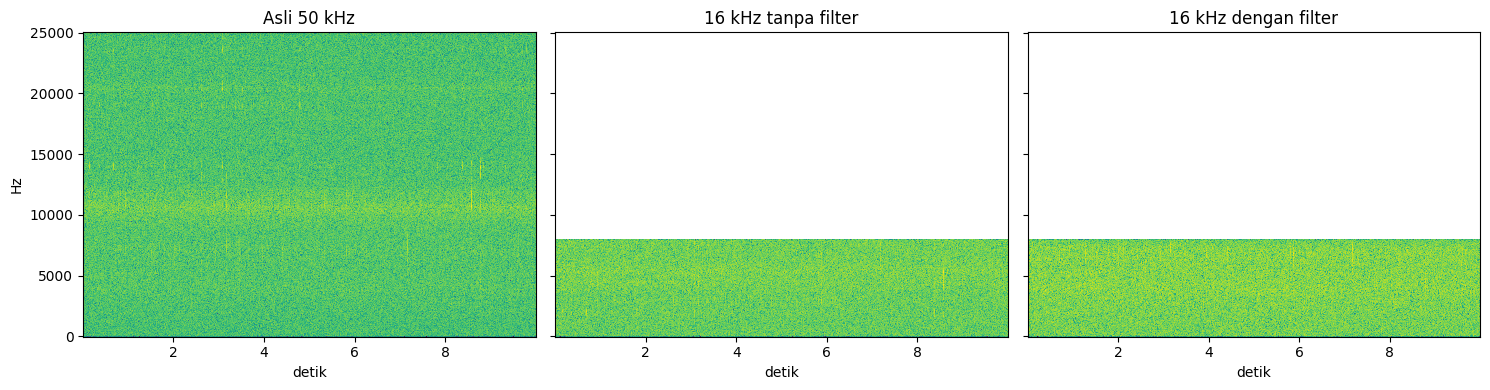

In [15]:
fn = 16000
data = [("Asli 50 kHz", x, fs),
        ("16 kHz tanpa filter", tanpa_filter(x, fs, fn), fn),
        ("16 kHz dengan filter", dengan_filter(x, fs, fn), fn)]
fig, ax = plt.subplots(1, 3, figsize=(15, 4), sharey=True)
for a, (judul, s, f_) in zip(ax, data):
    ff, tt, S = spectrogram(s, f_, nperseg=int(f_*0.02), noverlap=int(f_*0.01))
    a.pcolormesh(tt, ff, 10*np.log10(S + 1e-12), shading="auto")
    a.set_title(judul); a.set_xlabel("detik")
ax[0].set_ylabel("Hz")
plt.tight_layout()
plt.savefig("../results/aliasing_A5.png", dpi=150)
plt.show()

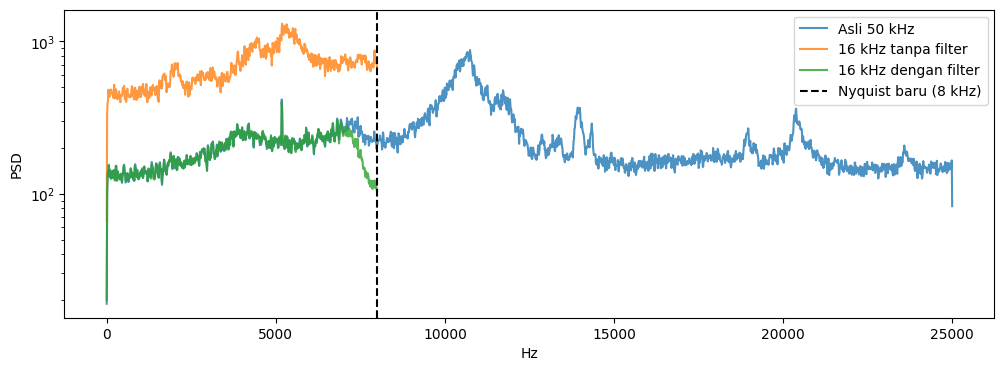

In [16]:
fn = 16000
f0, P0 = welch(x, fs, nperseg=4096)
y1 = tanpa_filter(x, fs, fn)
y2 = dengan_filter(x, fs, fn)
f1, P1 = welch(y1, fn, nperseg=int(round(4096*fn/fs)))
f2, P2 = welch(y2, fn, nperseg=int(round(4096*fn/fs)))

plt.figure(figsize=(12, 4))
plt.semilogy(f0, P0, label="Asli 50 kHz", alpha=0.8)
plt.semilogy(f1, P1, label="16 kHz tanpa filter", alpha=0.8)
plt.semilogy(f2, P2, label="16 kHz dengan filter", alpha=0.8)
plt.axvline(fn/2, color="k", linestyle="--", label="Nyquist baru (8 kHz)")
plt.xlabel("Hz"); plt.ylabel("PSD")
plt.legend()
plt.savefig("../results/psd_aliasing_A5.png", dpi=150)
plt.show()

In [17]:
def analisis(nama, fn_plot=16000):
    fs, x = wavfile.read(f"../data/raw/{nama}.wav")
    x = x.astype(float) - x.astype(float).mean()
    kode = nama.split("-")[0]

    # frekuensi puncak (cek garis tajam)
    f = np.fft.rfftfreq(len(x), 1/fs)
    P = np.abs(np.fft.rfft(x))**2
    print(kode, "| fs =", fs, "| frekuensi puncak =", round(f[np.argmax(P)]), "Hz")

    # tabel resampling
    baris = []
    for fs_baru in [25000, 16000, 12500, 8000]:
        if fs_baru >= fs:
            continue
        y1 = tanpa_filter(x, fs, fs_baru)
        y2 = dengan_filter(x, fs, fs_baru)
        baris.append({
            "fs_baru": fs_baru,
            "energi_hilang_pct": round(energi_hilang(x, fs, fs_baru), 1),
            "lsd_tanpa_filter_dB": round(lsd(x, fs, y1, fs_baru), 2),
            "lsd_dengan_filter_dB": round(lsd(x, fs, y2, fs_baru), 2),
        })
    tabel = pd.DataFrame(baris)
    tabel.to_csv(f"../results/resampling_{kode}.csv", index=False)

    # grafik PSD
    f0, P0 = welch(x, fs, nperseg=4096)
    y1 = tanpa_filter(x, fs, fn_plot)
    y2 = dengan_filter(x, fs, fn_plot)
    nper = int(round(4096*fn_plot/fs))
    f1, P1 = welch(y1, fn_plot, nperseg=nper)
    f2, P2 = welch(y2, fn_plot, nperseg=nper)
    plt.figure(figsize=(12, 4))
    plt.semilogy(f0, P0, label=f"Asli {fs//1000} kHz", alpha=0.8)
    plt.semilogy(f1, P1, label=f"{fn_plot//1000} kHz tanpa filter", alpha=0.8)
    plt.semilogy(f2, P2, label=f"{fn_plot//1000} kHz dengan filter", alpha=0.8)
    plt.axvline(fn_plot/2, color="k", linestyle="--", label="Nyquist baru")
    plt.title(kode); plt.xlabel("Hz"); plt.ylabel("PSD"); plt.legend()
    plt.savefig(f"../results/psd_aliasing_{kode}.png", dpi=150)
    plt.show()
    return tabel

A6 | fs = 50000 | frekuensi puncak = 5185 Hz


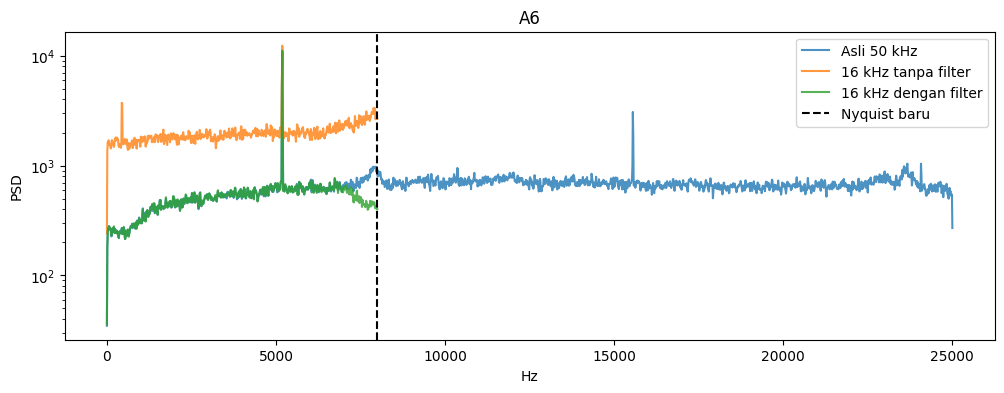

,fs_baru,energi_hilang_pct,lsd_tanpa_filter_dB,lsd_dengan_filter_dB
0,25000,52.3,3.63,0.01
1,16000,72.4,6.03,0.09
2,12500,80.0,7.78,0.01
3,8000,89.6,10.36,0.07


In [18]:
analisis("A6-w30khzrw1")

A3 | fs = 25000 | frekuensi puncak = 5183 Hz


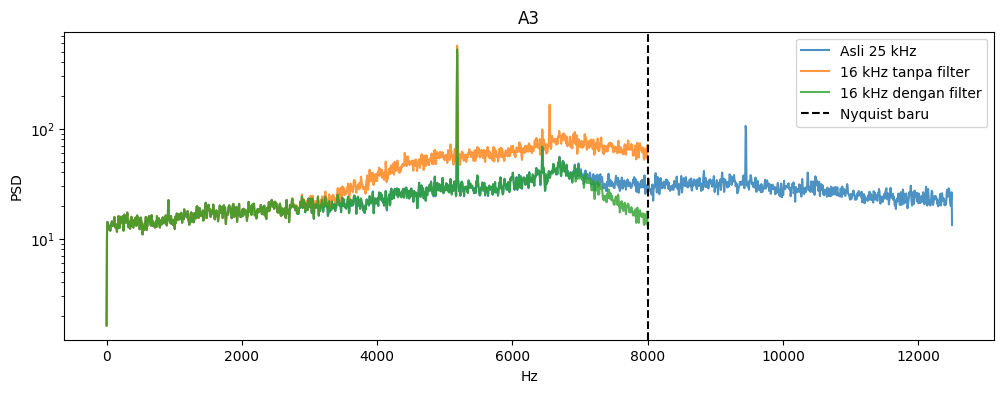

,fs_baru,energi_hilang_pct,lsd_tanpa_filter_dB,lsd_dengan_filter_dB
0,16000,39.0,1.80,0.07
1,12500,58.0,4.04,0.01
2,8000,78.8,7.05,0.07


In [20]:
analisis("A3-pvdfrw1")

A4 | fs = 25000 | frekuensi puncak = 0 Hz


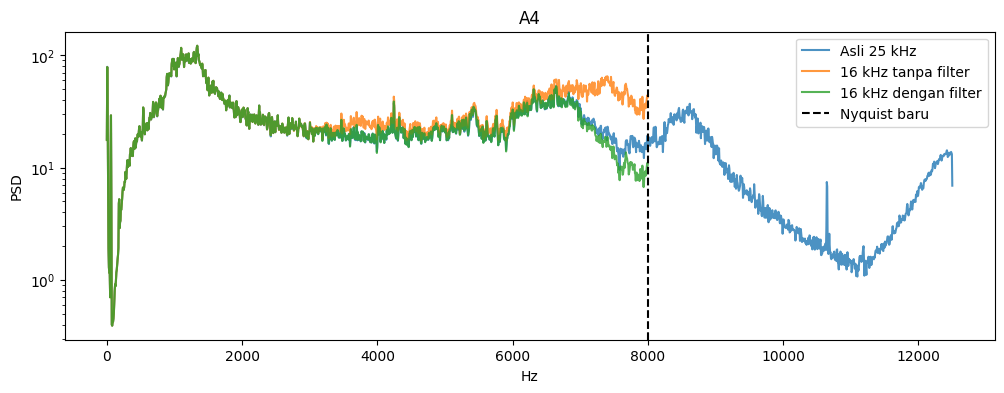

,fs_baru,energi_hilang_pct,lsd_tanpa_filter_dB,lsd_dengan_filter_dB
0,16000,13.7,0.48,0.04
1,12500,30.9,2.91,0.01
2,8000,48.3,5.02,0.07


A7 | fs = 25000 | frekuensi puncak = 2242 Hz


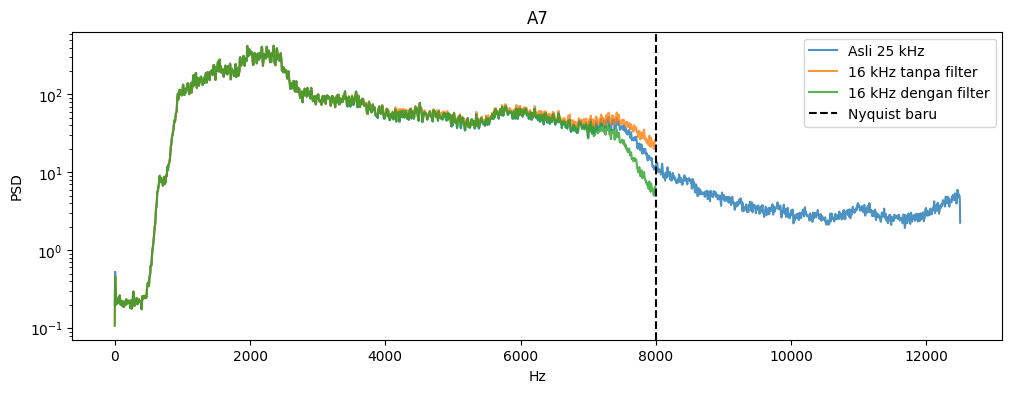

,fs_baru,energi_hilang_pct,lsd_tanpa_filter_dB,lsd_dengan_filter_dB
0,16000,2.8,0.19,0.09
1,12500,12.1,4.17,0.01
2,8000,29.5,9.44,0.10


A8 | fs = 20000 | frekuensi puncak = 243 Hz


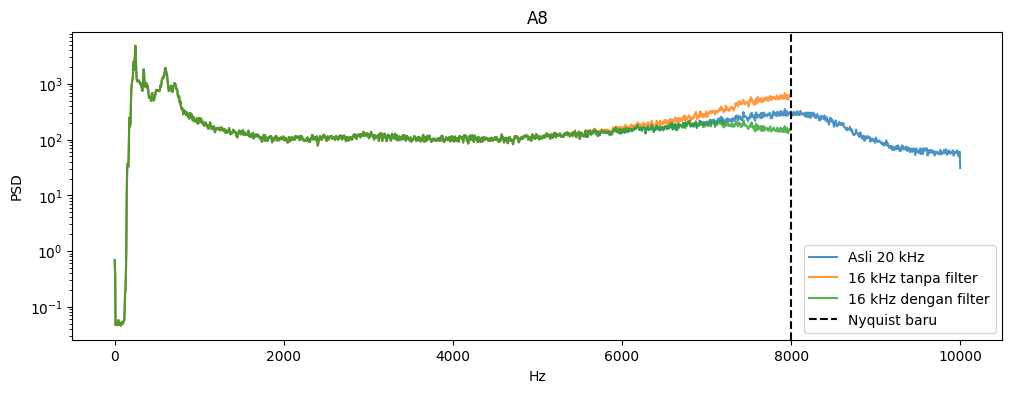

,fs_baru,energi_hilang_pct,lsd_tanpa_filter_dB,lsd_dengan_filter_dB
0,16000,14.0,0.18,0.03
1,12500,33.8,2.89,0.01
2,8000,47.7,8.91,0.04


A9 | fs = 20000 | frekuensi puncak = 257 Hz


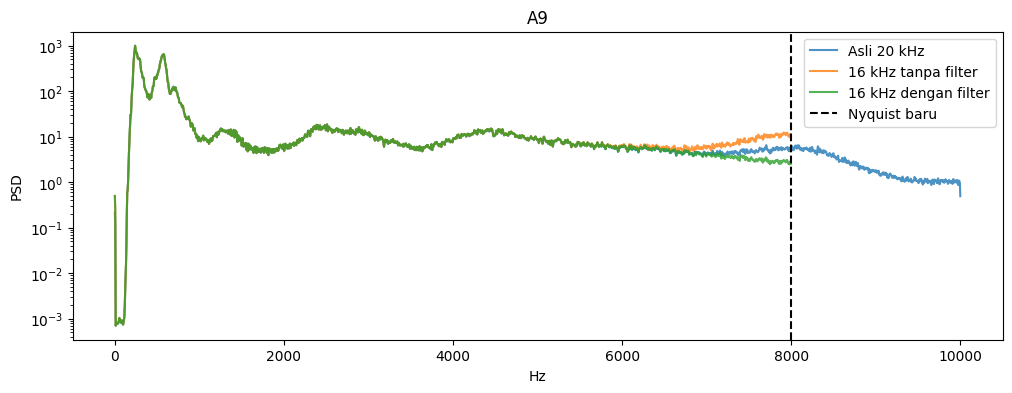

,fs_baru,energi_hilang_pct,lsd_tanpa_filter_dB,lsd_dengan_filter_dB
0,16000,2.3,0.18,0.15
1,12500,6.1,0.89,0.01
2,8000,14.7,8.41,0.05


In [22]:
from IPython.display import display

for nama in ["A4-accelrw", "A7-piezorw1", "A8-sz-lm3r1_f3-0s", "A9-sza-mar1f5-0s"]:
    display(analisis(nama))

In [23]:
import glob
rekap = pd.concat([pd.read_csv(f).assign(file=f.split("_")[-1][:-4]) for f in sorted(glob.glob("../results/resampling_A*.csv"))], ignore_index=True)
rekap.to_csv("../results/rekap_resampling.csv", index=False)
rekap

,fs_baru,energi_hilang_pct,lsd_tanpa_filter_dB,lsd_dengan_filter_dB,file
0,16000,39.0,1.80,0.07,A3
1,12500,58.0,4.04,0.01,A3
2,8000,78.8,7.05,0.07,A3
3,16000,13.7,0.48,0.04,A4
4,12500,30.9,2.91,0.01,A4
5,8000,48.3,5.02,0.07,A4
6,25000,39.4,2.63,0.01,A5
7,16000,71.1,5.56,0.07,A5
8,12500,79.0,7.21,0.01,A5
9,8000,88.1,9.58,0.07,A5
